# Task 3 - Overlap Management (adult census)
AI use: Claude was used to  understand some concepts that were quite confusing.

In [11]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("../../Datasets/adult.csv")  
df = df.drop_duplicates()
df = df.replace("?", np.nan).dropna()
df = df[["age", "education.num", "hours.per.week", "income"]].reset_index(drop=True)
print(df.shape)

(30139, 4)


<Axes: xlabel='age', ylabel='hours.per.week'>

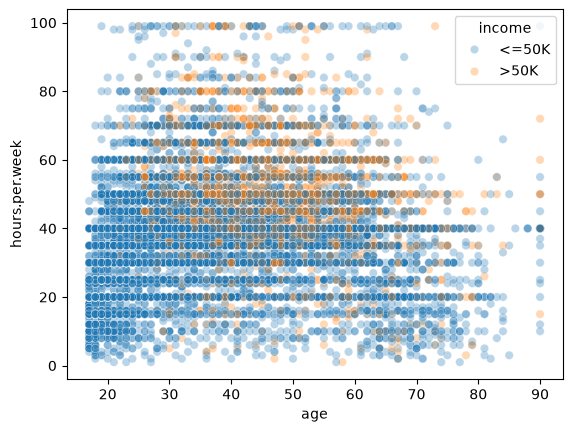

In [12]:
# Now let's take a particularly nasty overlap. Here.
sns.scatterplot(df, x="age", y="hours.per.week", hue="income", alpha=0.3)

# In real life, does this overlap seem feasable? Probably.
# There's always some overlap (especially in health diagnosis data).

# But say this didn't reflect reality and there's some reason to 
# fix the overlap (to which there are many)...

* I use the adult dataset with the numeric features age, education.num and hours.per.week, and income as the target. The scatterplot shows that the two income classes overlap strongly: people with <=50K and >50K are mixed in the same age and working-hours area. This is the overlap problem that TomekLinks tries to reduce.

In [13]:
from imblearn.under_sampling import TomekLinks

df = df.dropna()

# X y split to prevent data leakage
X = df.drop(columns="income", axis=1)
y = df["income"]

# Let's use vanilla tomeklinks
tomek = TomekLinks()

# Fit and resample.
X_resampled, y_resampled = tomek.fit_resample(X, y)

# Make a new copy (so we don't have trouble with dependency)
df_resampled = X_resampled.copy()

# Add y back into the X rows
df_resampled["income"] = y_resampled

In [14]:
df.shape

(30139, 4)

In [15]:
df_resampled.shape

(29984, 4)

In [16]:
df["income"].value_counts()

income
<=50K    22633
>50K      7506
Name: count, dtype: int64

In [17]:
df_resampled["income"].value_counts()

income
<=50K    22478
>50K      7506
Name: count, dtype: int64

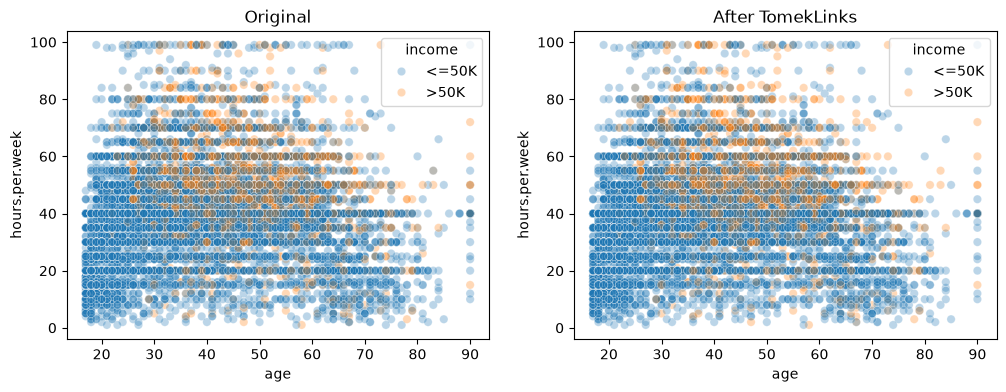

In [18]:
# Let's visualize the difference between the original and the resampled data.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(df, x="age", y="hours.per.week", hue="income", alpha=0.3, ax=axes[0])
sns.scatterplot(df_resampled, x="age", y="hours.per.week", hue="income", alpha=0.3, ax=axes[1])
axes[0].set_title("Original")
axes[1].set_title("After TomekLinks")
plt.show()

### Conclusion

* TomekLinks: TomekLinks finds pairs of rows from different classes that are each other's nearest neighbours (Tomek links). These pairs lie on the class border. It removes the majority-class row of each pair (<=50K), which cleans the border between the classes. (note for myself)

* Results: The dataset went from 30,139 to 29,984 rows, so 155 rows were removed, all from the majority class <=50K (22,633 > 22,478). The minority class >50K was not changed (7,506). The scatterplots before and after look almost the same. This is expected: TomekLinks is a conservative method and only removes rows directly at the border. The overlap between the classes is still there, because age, education.num and hours.per.week alone cannot separate the two income groups. The class balance also barely changed (24.9% >50K >> 25.0%), so TomekLinks cleans the border but does not fix the imbalance.

## SmoteTomek

In [19]:
from imblearn.combine import SMOTETomek

# X y split to prevent data leakage
X = df.drop(columns="income", axis=1)
y = df["income"]

# Initialize the SmoteTomek object
smote_tomek = SMOTETomek(
    random_state=321
)

# And fit it with all of the features in the dataset.
X_resampled, y_resampled = smote_tomek.fit_resample(X, y)

# Make a new copy (so we don't have trouble with dependency)
df_st = X_resampled.copy()

# Add y back into the X rows
df_st["income"] = y_resampled
df_st

,age,education.num,hours.per.week,income
0,82,9,18,<=50K
1,54,4,40,<=50K
2,41,10,40,<=50K
3,34,9,45,<=50K
4,38,6,40,<=50K
...,...,...,...,...
45107,63,4,60,>50K
45108,44,15,40,>50K
45109,28,13,29,>50K
45110,46,15,40,>50K


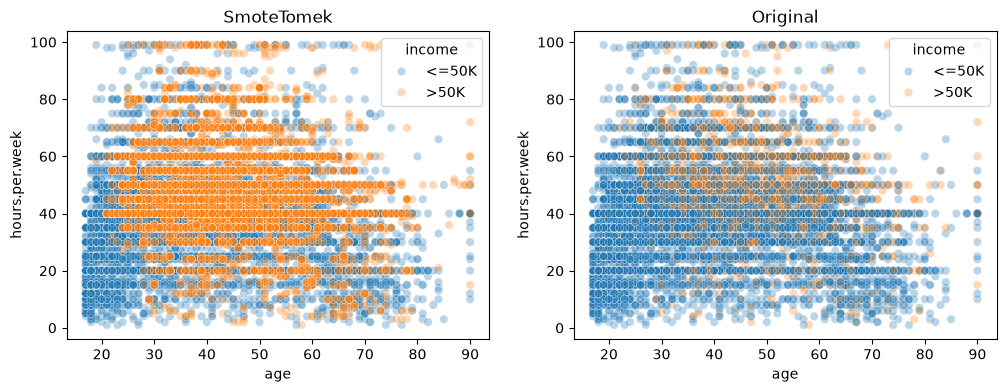

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(df_st, x="age", y="hours.per.week", hue="income", alpha=0.3, ax=axes[0])
sns.scatterplot(df, x="age", y="hours.per.week", hue="income", alpha=0.3, ax=axes[1])
axes[0].set_title("SmoteTomek")
axes[1].set_title("Original")
plt.show()

In [21]:
df.shape

(30139, 4)

In [22]:
df_st.shape

(45112, 4)

In [23]:
df["income"].value_counts()

income
<=50K    22633
>50K      7506
Name: count, dtype: int64

In [24]:
df_st["income"].value_counts()

income
<=50K    22556
>50K     22556
Name: count, dtype: int64

* extra/advanced task: SmoteTomek. SmoteTomek combines two steps: SMOTE adds synthetic rows for the minority class (>50K), then TomekLinks removes rows at the class border. The dataset went from 30,139 to 45,112 rows. SMOTE added 15,127 synthetic >50K rows, and Tomek removed 154 rows (77 from each class). Both classes now have 22,556 rows (50/50).

* Comparison with TomekLinks alone: TomekLinks alone removed 155 rows and left the imbalance (25% >50K). SmoteTomek also fixes the imbalance, but the border cleaning is just as small (about 150 rows), so the overlap in the scatterplot is still there. 

* Why is SmoteTomek effective for overlap?
SMOTE balances the classes by creating synthetic minority rows, but it does not clean the class border, and it can even create new rows inside the overlap area. TomekLinks cleans the border by removing opposite-class neighbour pairs, but alone it is very conservative and does not fix the imbalance (in my data it removed only 155 rows). Together, SMOTE first balances the classes and TomekLinks then removes the border pairs, including noisy synthetic rows. Each method fixes the weakness of the other.

* I used Claude to explain some things that were not clear to me. I checked it against the prof's lecture notebook and my own results.